# **Phase 3B: 2018 Analysis**

This notebook answers seven business questions about the Seoul Bike Rentals in 2018.

Demand means completed rentals. The data holds no record of requests that went unmet.

## **Step 0: Import all Necessary Libraries**

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import pandas as pd
import numpy as np
import calendar

sys.path.append("..")

from src.clean import (
    load_clean,
    CLEAN_FILE,
)

from src.analysis import (
    daily_table,
    headline_figures,
    to_full_calendar,
    rolling_average,
    daily_weather,
    monthly_summary,
    monthly_highlights,
    season_summary,
    season_highlights,
    hour_profile_by_day_type,
    hour_profile_by_season,
    hour_peaks,
    time_block_share,
    week_weekday_matrix,
    weekly_summary,
    weekday_comparison,
    weekly_highlights,
    lowest_day_by_week,
    weather_daily_table,
    season_correlations,
    season_weather_means,
    rain_effect,
    holiday_vs_peers,
    day_type_summary,
    closed_dates_table,
    partial_dates,
    winter_comparison,
    winter_gap,
    sunday_gap,
    ALL_YEAR_LABEL,
    WEATHER_FACTORS,
    WEEK_ORDER,
    HOLIDAYS,
    SEASON_BY_MONTH,
    SEASON_ORDER
)

from src.dashboards_2018 import (
    dashboard_volume,
    dashboard_months,
    dashboard_seasons,
    dashboard_hours,
    dashboard_weekdays,
    dashboard_weather,
    dashboard_holidays,
)

CLEAN_DIR = Path("../data/clean")
FIG_DIR = Path("../reports/figures")

## **Step 1: Load and Filter the Data**

In [2]:
clean_df = load_clean(CLEAN_DIR / CLEAN_FILE)

# mask out the year
is_2018 = clean_df["year"] == 2018

# filter out the masked data
df18 = clean_df[is_2018].copy()

## **Step 2: Daily Series**

In [3]:
daily = daily_table(df18)
display(daily)

day_type_counts = daily.groupby("day_type")["date"].count()

,date,day_name,week_number,daily_rentals,day_type
0,2018-01-01,Monday,5,4290,Holiday
1,2018-01-02,Tuesday,5,6446,Weekday
2,2018-01-03,Wednesday,5,6512,Weekday
3,2018-01-04,Thursday,5,6453,Weekday
4,2018-01-05,Friday,6,6967,Weekday
...,...,...,...,...,...
317,2018-11-26,Monday,52,17162,Weekday
318,2018-11-27,Tuesday,52,16282,Weekday
319,2018-11-28,Wednesday,52,16524,Weekday
320,2018-11-29,Thursday,52,16423,Weekday


## **Step 3: Tiles**

In [4]:
tiles = headline_figures(daily)

display(tiles)

{'total_rentals': 5986984,
 'open_dates': 322,
 'mean_per_day': 18593.11801242236,
 'busiest_date': Timestamp('2018-06-13 00:00:00'),
 'busiest_day_name': 'Wednesday',
 'busiest_rentals': 36149,
 'quietest_date': Timestamp('2018-04-23 00:00:00'),
 'quietest_day_name': 'Monday',
 'quietest_rentals': 977}

## **Step 4: Closed Dates**

In [5]:
CALENDAR_START = "2018-01-01"
CALENDAR_END = "2018-11-30"

# The calendar needs a series indexed by date
daily_rentals = daily.set_index("date")["daily_rentals"]

full_calendar = to_full_calendar(
    daily_rentals,
    start=CALENDAR_START,
    end=CALENDAR_END,
)

rolling_avg = rolling_average(full_calendar)

print(f"Daily series: {len(daily_rentals)} dates")
print(f"Full calendar: {len(full_calendar)} dates, {full_calendar.isna().sum()} empty")

Daily series: 322 dates
Full calendar: 334 dates, 12 empty


## **Step 5: Assertions**

In [6]:
# Expected values

EXPECTED_OPEN_DATES = 322
EXPECTED_CALENDAR_DATES = 334
EXPECTED_EMPTY_DATES = 12

EXPECTED_TOTAL_RENTALS = df18["rented_bike_count"].sum()    # from the hourly table

EXPECTED_ABSENT_DATES = {
    "2018-04-11",
    "2018-05-10",
    "2018-09-18",
    "2018-09-19",
    "2018-09-28",
    "2018-09-30",
    "2018-10-02",
    "2018-10-04",
    "2018-10-09",
    "2018-11-03",
    "2018-11-06",
    "2018-11-09",
}
absent_dates = pd.DatetimeIndex(EXPECTED_ABSENT_DATES)

# 1. Daily rentals total must equal the hourly table total

actual_daily_total = daily["daily_rentals"].sum()

assert actual_daily_total == EXPECTED_TOTAL_RENTALS, (
    f"Daily rentals total mismatch: EXPECTED {EXPECTED_TOTAL_RENTALS}, "
    f"Got {actual_daily_total}"
)

assert tiles["total_rentals"] == EXPECTED_TOTAL_RENTALS, (
    f"Total rentals tile mismatch: EXPECTED {EXPECTED_TOTAL_RENTALS}, "
    f"Got {tiles['total_rentals']}"
)


# 2. Daily table and full calendar sizes

assert len(daily) == EXPECTED_OPEN_DATES, (
    f"Open dates mismatch: EXPECTED {EXPECTED_OPEN_DATES}, "
    f"Got {len(daily)}"
)

assert len(full_calendar) == EXPECTED_CALENDAR_DATES, (
    f"Calendar dates mismatch: EXPECTED {EXPECTED_CALENDAR_DATES}, "
    f"Got {len(full_calendar)}"
)

empty_dates = full_calendar.index[full_calendar.isna()]

assert len(empty_dates) == EXPECTED_EMPTY_DATES, (
    f"Empty dates mismatch: EXPECTED {EXPECTED_EMPTY_DATES}, "
    f"Got {len(empty_dates)}"
)


# 3. Mean multiplied by open dates must equal total rentals

actual_total_from_mean = tiles["mean_per_day"] * tiles["open_dates"]

assert np.isclose(actual_total_from_mean, tiles["total_rentals"]), (
    f"Mean and total mismatch: EXPECTED {tiles['total_rentals']}, "
    f"Got {actual_total_from_mean}"
)


# 4. Empty calendar dates must match the audit notebook

actual_absent_dates = set(empty_dates.strftime("%Y-%m-%d"))

assert actual_absent_dates == EXPECTED_ABSENT_DATES, (
    f"Absent dates mismatch: EXPECTED {sorted(EXPECTED_ABSENT_DATES)}, "
    f"Got {sorted(actual_absent_dates)}"
)


# 5. Busiest and quietest rentals must equal the sum of their hourly rows

expected_busiest_rentals = df18.loc[
    df18["date"].eq(tiles["busiest_date"]), "rented_bike_count"
].sum()

expected_quietest_rentals = df18.loc[
    df18["date"].eq(tiles["quietest_date"]), "rented_bike_count"
].sum()

assert tiles["busiest_rentals"] == expected_busiest_rentals, (
    f"Busiest rentals mismatch: EXPECTED {expected_busiest_rentals}, "
    f"Got {tiles['busiest_rentals']}"
)

assert tiles["quietest_rentals"] == expected_quietest_rentals, (
    f"Quietest rentals mismatch: EXPECTED {expected_quietest_rentals}, "
    f"Got {tiles['quietest_rentals']}"
)


# 6. Rolling average must be empty on every closed date

assert rolling_avg.loc[absent_dates].isna().all(), (
    "Rolling average holds values on closed dates: "
    f"{sorted(rolling_avg.loc[absent_dates].dropna().index)}"
)

print("All Question 1 Assertions PASSED.")

All Question 1 Assertions PASSED.


## **Step 6: Question 1 Dashboard**

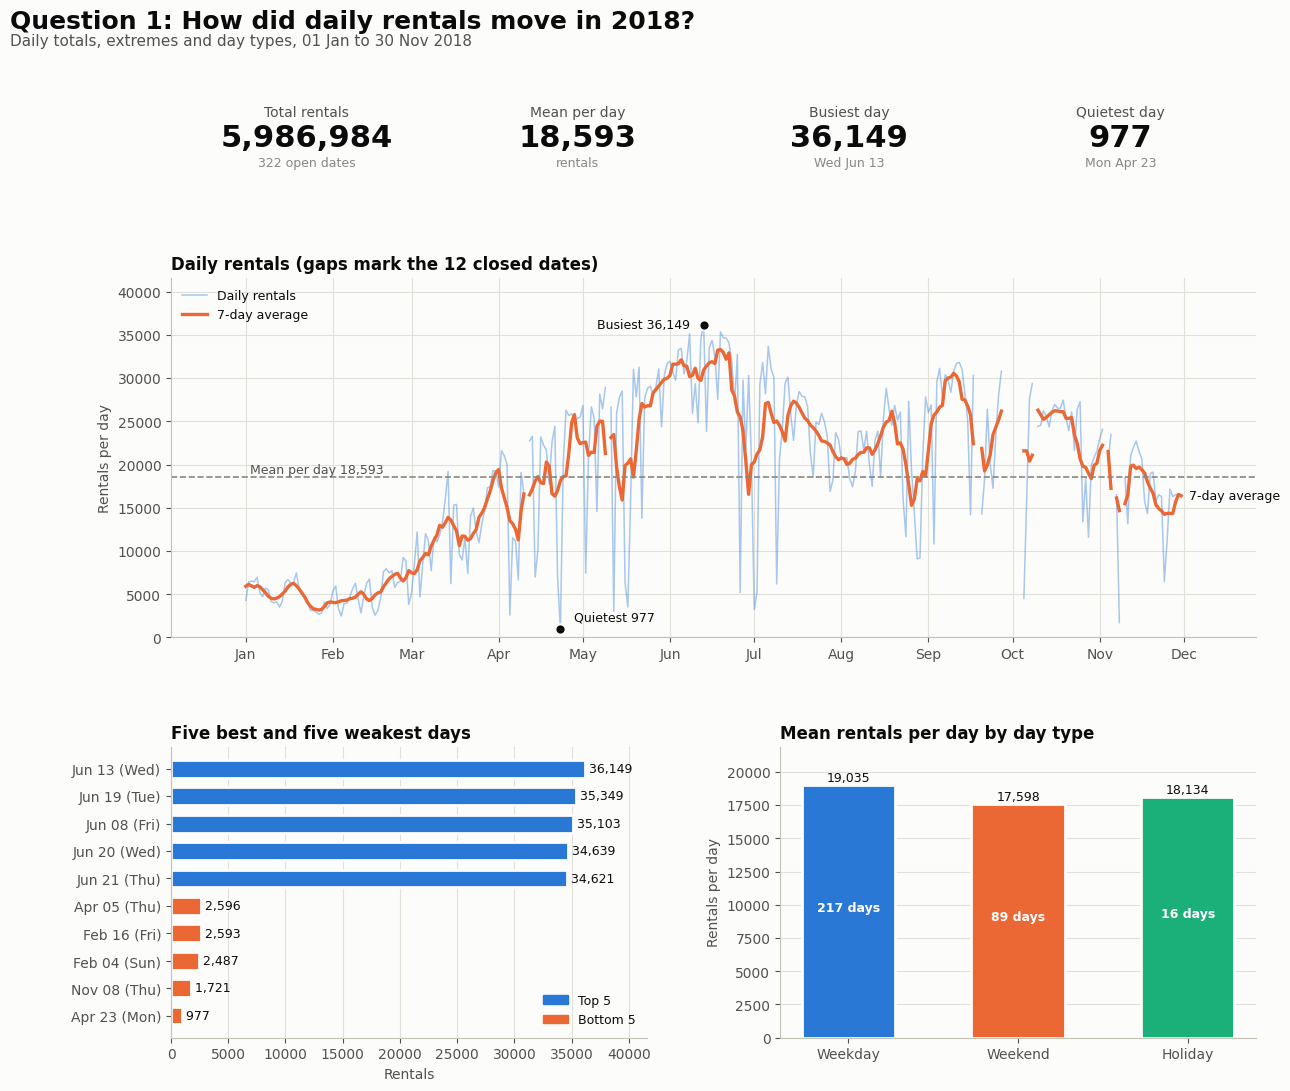

In [7]:
fig = dashboard_volume(
    tiles,
    daily,
    full_calendar,
    rolling_avg,
    save_path= FIG_DIR / "q1_volume_dashboard_2018.png"
)

## **Step 7: Weather Table and Monthly Table**

In [8]:
weather = daily_weather(df18)

print("WEATHER TABLE: ")
display(weather)

monthly = monthly_summary(daily, weather)
print("\nMONTHLY SUMMARY: ")
display(monthly)

print(f"\nMONTHLY HIGHLIGHTS      ")
highlights = monthly_highlights(monthly)
display(highlights)

WEATHER TABLE: 


,date,temperature,humidity,rainfall,snowfall
0,2018-01-01,-1.283333,39.333333,0.0,0.0
1,2018-01-02,-1.491667,43.708333,0.0,0.0
2,2018-01-03,-4.479167,41.166667,0.0,0.0
3,2018-01-04,-4.800000,44.125000,0.0,0.0
4,2018-01-05,-2.912500,48.541667,0.0,0.0
...,...,...,...,...,...
317,2018-11-26,6.320833,70.500000,0.0,2.9
318,2018-11-27,7.066667,68.000000,0.0,0.0
319,2018-11-28,5.304167,25.791667,0.0,0.0
320,2018-11-29,3.304167,38.000000,0.0,0.0



MONTHLY SUMMARY: 


,month,month_name,open_dates,total_rentals,mean_daily_rentals,change_vs_prev_pct,mean_temperature,mean_daily_rainfall,mean_daily_snowfall
0,1,January,31,150006,4838.903226,NaN,-3.943145,0.274194,6.129032
1,2,February,28,151833,5422.607143,12.062732,-1.664732,0.985714,2.450000
2,3,March,31,380594,12277.225806,126.408174,8.044489,1.661290,0.000000
3,4,April,29,524227,18076.793103,47.238418,12.950862,4.493103,0.000000
4,5,May,30,707088,23569.600000,30.385959,18.233472,7.400000,0.000000
5,6,June,30,896887,29896.233333,26.842345,23.136806,5.716667,0.000000
6,7,July,31,734460,23692.258065,-20.751695,27.763978,5.987097,0.000000
7,8,August,31,651887,21028.612903,-11.242682,28.736425,6.535484,0.000000
8,9,September,26,673612,25908.153846,23.204293,21.748718,2.626923,0.000000
9,10,October,28,650675,23238.392857,-10.304713,12.736686,3.553571,0.000000



MONTHLY HIGHLIGHTS      


{'biggest_monthly_rise': 'March',
 'biggest_rise_pct': 126.40817383615234,
 'lowest_month': 'January',
 'lowest_mean': 4838.903225806452,
 'highest_month': 'June',
 'highest_mean': 29896.233333333334}

## **Step 8: Assertions**

In [9]:
EXPECTED_MONTH_DATES = {
    1: 31,
    2: 28,
    3: 31,
    4: 29,
    5: 30,
    6: 30,
    7: 31,
    8: 31,
    9: 26,
    10: 28,
    11: 27,
}

EXPECTED_MONTHLY_ROWS = len(EXPECTED_MONTH_DATES)
PERCENTAGE_MULTIPLIER = 100

WEATHER_COLUMNS = [
    "mean_temperature",
    "mean_daily_rainfall",
    "mean_daily_snowfall"
]

# 1. Verify monthly open dates against the audit.

actual_month_dates = dict(
    zip(monthly["month"], monthly["open_dates"])
)

assert actual_month_dates == EXPECTED_MONTH_DATES, (
    f"Monthly open dates mismatch: "
    f"expected {EXPECTED_MONTH_DATES}, Got {actual_month_dates}"
)

# 2. Compare rental totals for every month against hourly data.

expected_monthly_rentals = (
    df18.groupby("month")["rented_bike_count"]
    .sum()
    .reindex(monthly["month"])
    .to_numpy()
)

actual_monthly_rentals = monthly["total_rentals"].to_numpy()

assert np.array_equal(
    actual_monthly_rentals, expected_monthly_rentals
), (
    f"Monthly rental totals mismatch: "
    f"expected {expected_monthly_rentals.tolist()}, "
    f"Got {actual_monthly_rentals.tolist()}"
)

# 3. Verify mean daily rentals multiplied by open dates.

calculated_monthly_rentals = (
    monthly["mean_daily_rentals"] * monthly["open_dates"]
).to_numpy()

assert np.allclose(
    calculated_monthly_rentals, actual_monthly_rentals
), (
    f"Mean daily rentals mismatch: "
    f"expected {actual_monthly_rentals.tolist()}, "
    f"Got {calculated_monthly_rentals.tolist()}"
)

# 4. Verify January change and February change independently.

january = monthly.loc[monthly["month"] == 1].iloc[0]
february = monthly.loc[monthly["month"] == 2].iloc[0]

assert pd.isna(january["change_vs_prev_pct"]), (
    f"January change should be empty: "
    f"expected NaN, Got {january['change_vs_prev_pct']}"
)

expected_february_change = (
    (
        february["mean_daily_rentals"]
        - january["mean_daily_rentals"]
    )
    / january["mean_daily_rentals"]
) * PERCENTAGE_MULTIPLIER

actual_february_change = february["change_vs_prev_pct"]

assert np.isclose(
    actual_february_change, expected_february_change
), (
    f"February change mismatch: "
    f"expected {expected_february_change}, "
    f"Got {actual_february_change}"
)

# 5. Derive expected highlights independently from hourly rentals.

daily_totals = (
    df18.groupby("date")["rented_bike_count"]
    .sum()
    .rename("daily_rentals")
    .reset_index()
)

daily_totals["month"] = daily_totals["date"].dt.month

independent_monthly_means = (
    daily_totals.groupby("month")["daily_rentals"].mean()
)

independent_monthly_changes = (
    independent_monthly_means.pct_change()
    * PERCENTAGE_MULTIPLIER
)

expected_rise_month = independent_monthly_changes.idxmax()
expected_lowest_month = independent_monthly_means.idxmin()
expected_highest_month = independent_monthly_means.idxmax()

expected_rise_name = calendar.month_name[expected_rise_month]

expected_lowest_name = calendar.month_name[expected_lowest_month]

expected_highest_name = calendar.month_name[expected_highest_month]

assert highlights["biggest_monthly_rise"] == expected_rise_name, (
    f"Biggest rise month mismatch: "
    f"expected {expected_rise_name}, "
    f"Got {highlights['biggest_monthly_rise']}"
)

assert highlights["lowest_month"] == expected_lowest_name, (
    f"Lowest month mismatch: "
    f"expected {expected_lowest_name}, "
    f"Got {highlights['lowest_month']}"
)

assert highlights["highest_month"] == expected_highest_name, (
    f"Highest month mismatch: "
    f"expected {expected_highest_name}, "
    f"Got {highlights['highest_month']}"
)

assert np.isclose(
    highlights["biggest_rise_pct"],
    independent_monthly_changes.loc[expected_rise_month],
), (
    f"Biggest rise percentage mismatch: "
    f"expected {independent_monthly_changes.loc[expected_rise_month]}, "
    f"Got {highlights['biggest_rise_pct']}"
)

# 6. Verify monthly row count and complete weather values.

actual_monthly_rows = len(monthly)

assert actual_monthly_rows == EXPECTED_MONTHLY_ROWS, (
    f"Monthly row count mismatch: "
    f"expected {EXPECTED_MONTHLY_ROWS}, Got {actual_monthly_rows}"
)

missing_weather_counts = monthly[WEATHER_COLUMNS].isna().sum().to_dict()

assert monthly[WEATHER_COLUMNS].notna().all().all(), (
    f"Missing monthly weather values: "
    f"expected no missing values, Got {missing_weather_counts}"
)

# 7. Verify monthly rainfall and snowfall totals.

expected_rainfall_total = df18["rainfall"].sum()
calculated_rainfall_total = (
    monthly["mean_daily_rainfall"] * monthly["open_dates"]
).sum()

assert np.isclose(
    calculated_rainfall_total, expected_rainfall_total
), (
    f"Rainfall total mismatch: "
    f"expected {expected_rainfall_total}, "
    f"Got {calculated_rainfall_total}"
)

expected_snowfall_total = df18["snowfall"].sum()
calculated_snowfall_total = (
    monthly["mean_daily_snowfall"] * monthly["open_dates"]
).sum()

assert np.isclose(
    calculated_snowfall_total, expected_snowfall_total
), (
    f"Snowfall total mismatch: "
    f"expected {expected_snowfall_total}, "
    f"Got {calculated_snowfall_total}"
)

print("All Question 2 Assertion PASSED.")

All Question 2 Assertion PASSED.


## **Step 9: Question 2 Dashboard**

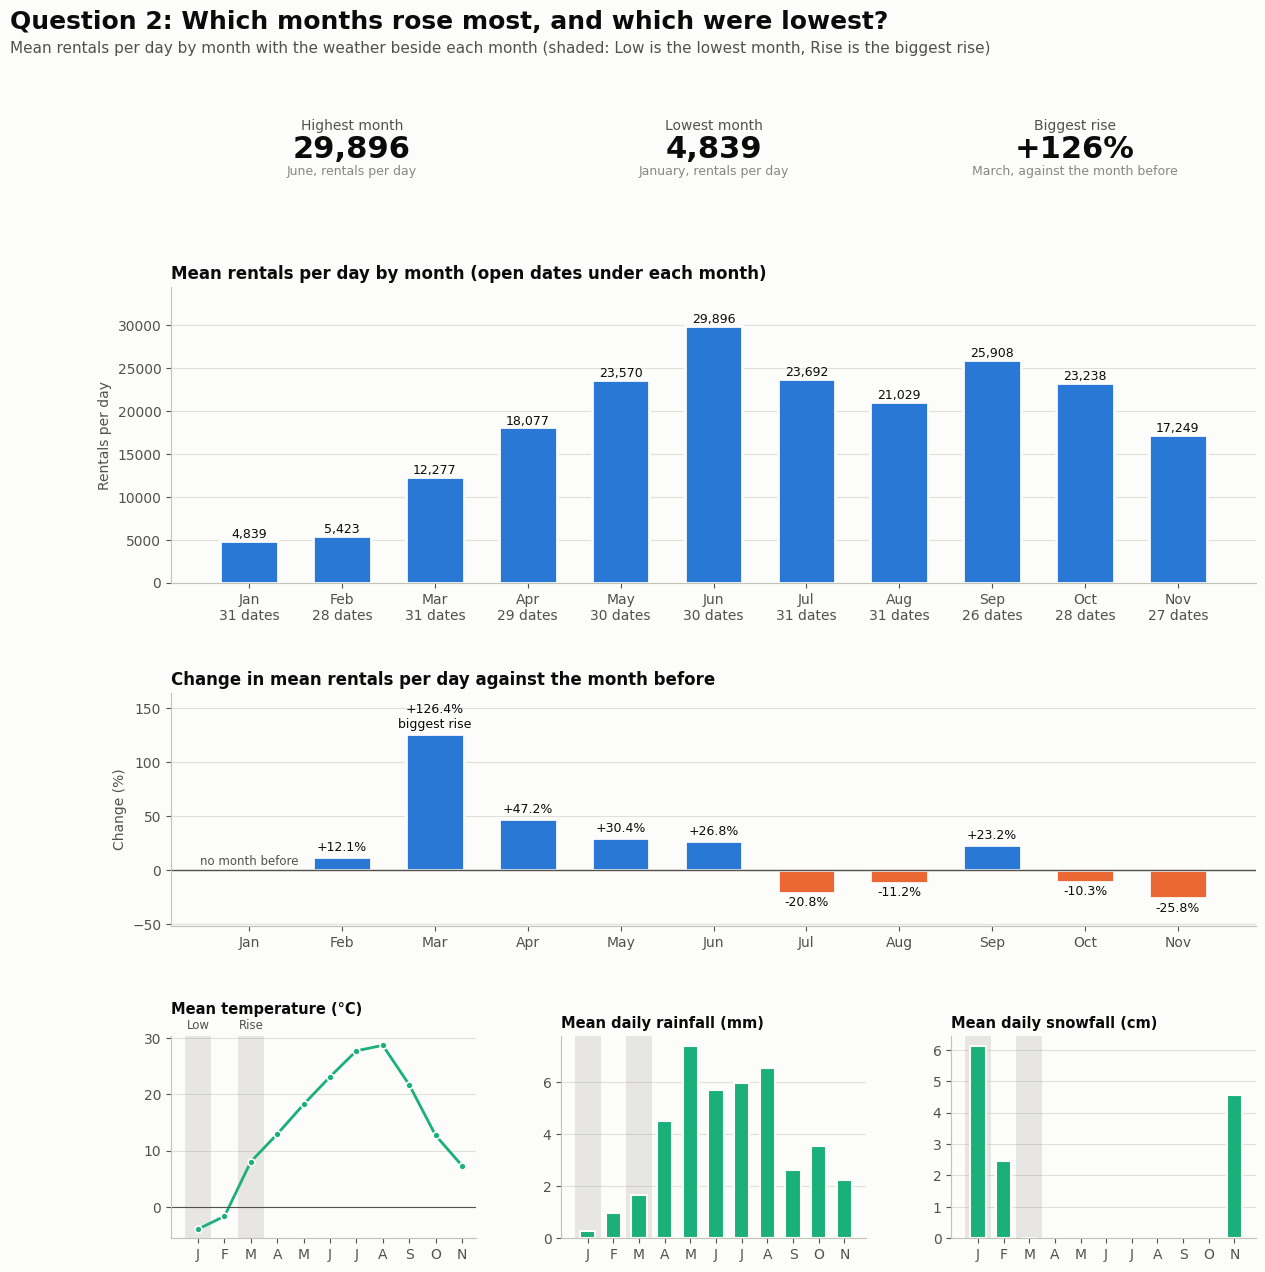

In [10]:
fig = dashboard_months(
    monthly,
    highlights,
    save_path= FIG_DIR / "q2_months_dashboard_2018.png"
)

**Key Insight: Question 2 Findings**

June leads at 29,896 rentals per day on average, yet the warmest months do not. June averaged 23.1 C. August averaged 28.7 C and fell to 21,029 (average rentals per day). March posted the biggest rise, +126.4% at 8 C with 1.66mm of rain per day and no snow. January was the lowest at 4,839 (average rentals per day), at -3.9 C with 0.27mm of rain and 6.13cm of snow per day. The table (monthly summary) shows association only, not cause. Rain, season and holidays also differ by month. Question 6 tests the link within each season.

## **Step 10: Season Table and Highlights** 

In [11]:
seasons = season_summary(daily)
season_stats = season_highlights(seasons)

display(seasons)
display(season_stats)

,season,open_dates,total_rentals,mean_daily_rentals,median_daily_rentals,lowest_day,highest_day,std_daily_rentals,spread_pct
0,Winter,59,301839,5115.915254,4813.0,2487,9247,1674.584645,32.732846
1,Spring,90,1611909,17910.100000,17590.0,977,31681,8357.148986,46.661655
2,Summer,92,2283234,24817.760870,25571.5,3231,36149,7297.344179,29.403717
3,Autumn,81,1790002,22098.790123,23350.0,1721,31809,6710.893394,30.367696


{'leading_season': 'Summer',
 'leading_mean': 24817.760869565216,
 'weakest_season': 'Winter',
 'weakest_mean': 5115.9152542372885,
 'season_gaps': {'Winter': {'gap_rentals': 19701.845615327926,
   'gap_pct': 79.38607241352263},
  'Spring': {'gap_rentals': 6907.660869565218, 'gap_pct': 27.833537867778773},
  'Autumn': {'gap_rentals': 2718.9707461084254,
   'gap_pct': 10.955745606537706}}}

## **Step 11: Assertions**

In [12]:
# Constants
EXPECTED_OPEN_DATES = [59, 90, 92, 81]
EXPECTED_TOTAL_OPEN_DATES = 322
WINTER = "Winter"

# Independently derive daily rentals from the hourly data.
daily18 = (
    df18.groupby("date")["rented_bike_count"]
    .sum()
    .rename("daily_rentals")
    .reset_index()
)

daily18["season"] = daily18["date"].dt.month.map(SEASON_BY_MONTH)

season_totals18 = (
    daily18.groupby("season")["daily_rentals"]
    .sum()
    .reindex(SEASON_ORDER)
)

season_means18 = (
    daily18.groupby("season")["daily_rentals"]
    .mean()
    .reindex(SEASON_ORDER)
)

winter_daily18 = daily18.loc[
    daily18["season"] == WINTER, "daily_rentals"
]

# 1. Open dates match the expected seasonal counts and total.
assert seasons["open_dates"].tolist() == EXPECTED_OPEN_DATES, (
    f"Open dates mismatch: "
    f"expected {EXPECTED_OPEN_DATES}, "
    f"got {seasons['open_dates'].tolist()}"
)

assert seasons["open_dates"].sum() == EXPECTED_TOTAL_OPEN_DATES, (
    f"Total open dates mismatch: "
    f"expected {EXPECTED_TOTAL_OPEN_DATES}, "
    f"got {seasons['open_dates'].sum()}"
)

# 2. Each seasonal total matches the hourly data.
assert seasons["total_rentals"].tolist() == season_totals18.tolist(), (
    f"Seasonal totals mismatch: "
    f"expected {season_totals18.tolist()}, "
    f"got {seasons['total_rentals'].tolist()}"
)

# 3. Mean daily rentals multiplied by open dates equals total rentals.
calculated_totals = (
    seasons["mean_daily_rentals"] * seasons["open_dates"]
)

assert np.allclose(
    calculated_totals,
    seasons["total_rentals"],
), (
    f"Mean times open dates mismatch: "
    f"expected {seasons['total_rentals'].tolist()}, "
    f"got {calculated_totals.tolist()}"
)

# 4. Leading season matches an independent calculation from df18.
expected_leader = season_means18.idxmax()
expected_leading_mean = season_means18.max()

assert season_stats["leading_season"] == expected_leader, (
    f"Leading season mismatch: "
    f"expected {expected_leader}, "
    f"got {season_stats['leading_season']}"
)

assert np.isclose(
    season_stats["leading_mean"],
    expected_leading_mean,
), (
    f"Leading mean mismatch: "
    f"expected {expected_leading_mean}, "
    f"got {season_stats['leading_mean']}"
)

# 5. Winter gap matches a hand calculation.
winter_mean = season_means18.loc[WINTER]
leader_mean = expected_leading_mean

expected_winter_gap = leader_mean - winter_mean
expected_winter_gap_pct = expected_winter_gap / leader_mean * 100

assert np.isclose(
    season_stats["season_gaps"][WINTER]["gap_rentals"],
    expected_winter_gap,
), (
    f"Winter rental gap mismatch: "
    f"expected {expected_winter_gap}, "
    f"got {season_stats['season_gaps'][WINTER]['gap_rentals']}"
)

assert np.isclose(
    season_stats["season_gaps"][WINTER]["gap_pct"],
    expected_winter_gap_pct,
), (
    f"Winter gap percent mismatch: "
    f"expected {expected_winter_gap_pct}, "
    f"got {season_stats['season_gaps'][WINTER]['gap_pct']}"
)

# 6. Winter median and standard deviation match direct calculations.
expected_winter_median = winter_daily18.median()
expected_winter_std = winter_daily18.std()

winter_row = seasons.loc[seasons["season"] == WINTER].iloc[0]

assert np.isclose(
    winter_row["median_daily_rentals"],
    expected_winter_median,
), (
    f"Winter median mismatch: "
    f"expected {expected_winter_median}, "
    f"got {winter_row['median_daily_rentals']}"
)

assert np.isclose(
    winter_row["std_daily_rentals"],
    expected_winter_std,
), (
    f"Winter standard deviation mismatch: "
    f"expected {expected_winter_std}, "
    f"got {winter_row['std_daily_rentals']}"
)

print("All Question 3 Assertion PASSED")

All Question 3 Assertion PASSED


## **Step 12: Question 3 Dashboard**

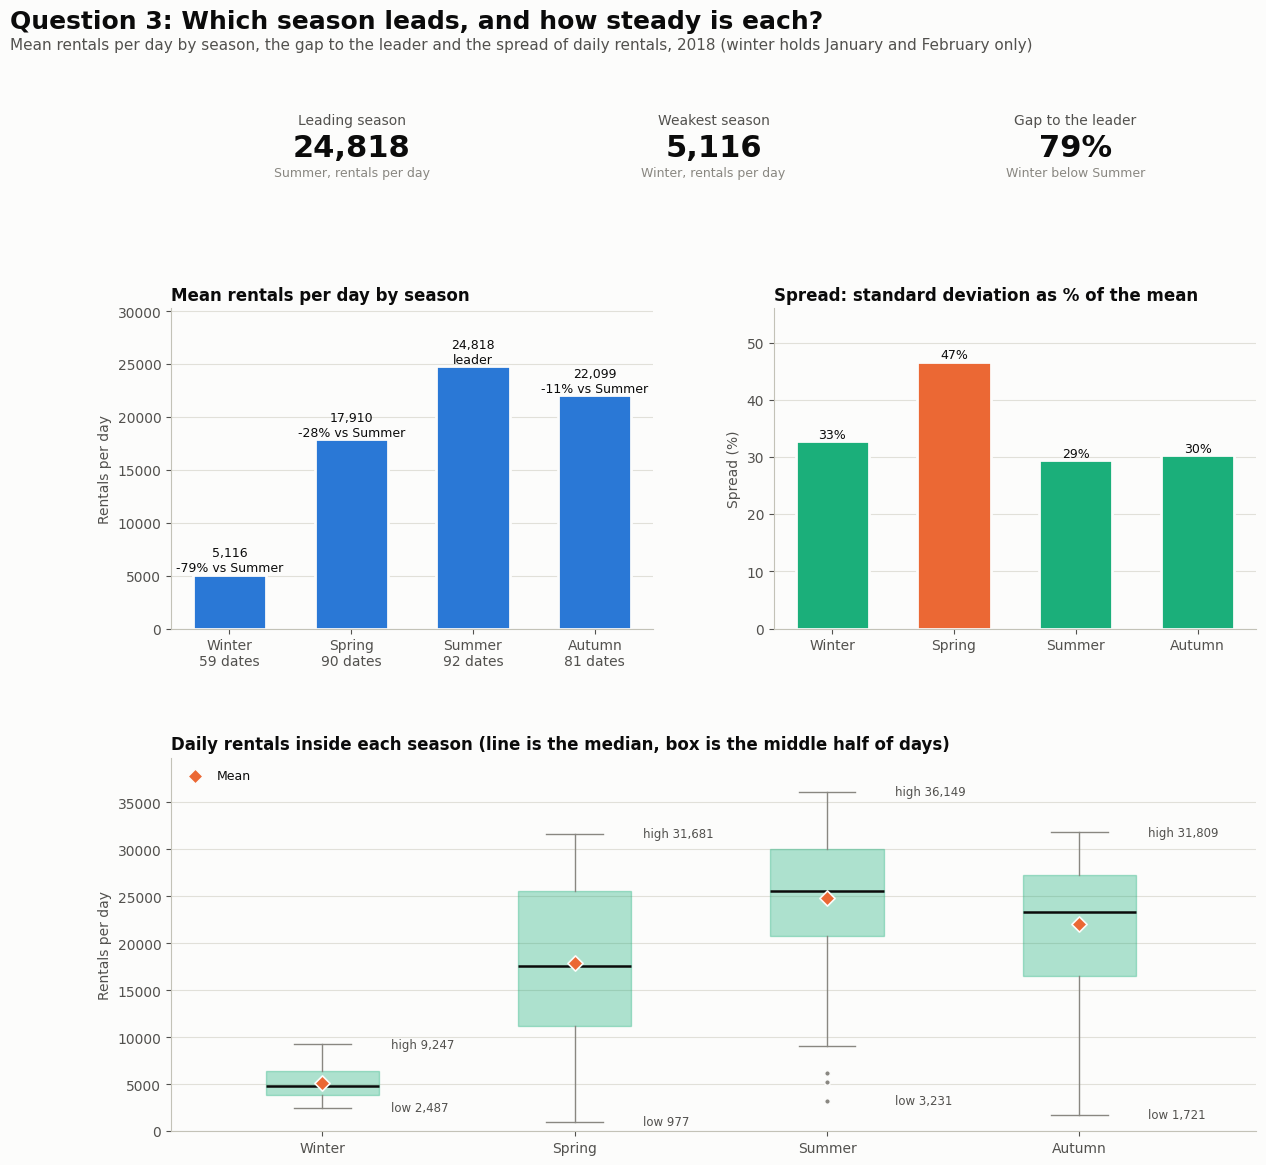

In [13]:
fig = dashboard_seasons(
    seasons,
    season_stats,
    daily,
    save_path=FIG_DIR / "q3_seasons_dashboard_2018.png"
)

**Key Insights: Question 3 Findings**

Summer leads with mean daily rentals of 24,818, followed by Autumn at 22,099, Spring at 17,910, and Winter at 5,116. Compared with Summer, Autumn records 2,719 fewer rentals per day (11% lower), Spring records 6,908 fewer (28% lower), and Winter records 19,702 fewer (79% lower). In terms of spread, Spring is the least steady season at 47% of its mean, while Winter, Summer, and Autumn have lower spreads of 33%, 29%, and 30%, respectively. Winter covers January and February only, with 59 open dates, because December 2018 is not in the data.

## **Step 13: Hourly Table and Day Types**

In [14]:
season_profiles = hour_profile_by_season(df18)
day_type_profiles = hour_profile_by_day_type(df18)

profiles = pd.concat(
    [season_profiles, day_type_profiles],
    axis=1,
)

peaks = hour_peaks(profiles)

print(f"Hourly Seasonal Profile: ")
display(season_profiles)

print(f"\nHourly Day Type Profile: ")
display(day_type_profiles)

print(f"\nPeak Profiles: ")
display(peaks)

season_shares = pd.DataFrame({
    season: time_block_share(
        df18[
            df18["month"].map(SEASON_BY_MONTH).eq(season)
        ]
    )
    for season in SEASON_ORDER
}).T

print(f"\nSeason Shares by Time Block")
display(season_shares)

Hourly Seasonal Profile: 


season,Winter,Spring,Summer,Autumn
hour,,,,
0,145.423729,481.088889,899.065217,709.437500
1,139.152542,363.944444,698.771739,552.500000
2,100.864407,252.966667,505.750000,377.475000
3,65.932203,168.477778,342.673913,256.550000
4,44.576271,108.222222,223.815217,169.025000
5,46.711864,116.177778,245.934783,163.412500
6,91.694915,257.233333,485.836957,359.487500
7,205.474576,615.288889,902.782609,788.876543
8,411.254237,1036.377778,1418.597826,1345.037037



Hourly Day Type Profile: 


day_type,Holiday,Weekday,Weekend
hour,,,
0,667.0000,540.050691,721.409091
1,544.1250,411.400922,584.909091
2,413.1875,278.866359,435.454545
3,290.8125,184.216590,300.852273
4,184.8125,125.105991,186.113636
5,128.8750,160.930876,135.534091
6,186.8125,384.133641,178.079545
7,286.8750,853.364055,277.348315
8,451.0000,1425.073733,455.505618



Peak Profiles: 


,morning_hour,morning_mean,evening_hour,evening_mean,quietest_hour
group,,,,,
Winter,8,411.254237,18,426.186441,4
Spring,8,1036.377778,18,1689.311111,4
Summer,8,1418.597826,18,2135.141304,4
Autumn,8,1345.037037,18,1983.333333,5
Holiday,11,767.250000,17,1336.812500,5
Weekday,8,1425.073733,18,1864.769585,4
Weekend,11,690.044944,17,1249.674157,5



Season Shares by Time Block


,Night (0-5),Morning (6-9),Midday (10-15),Evening (16-20),Late (21-23)
Winter,10.607311,18.660610,28.554627,30.562651,11.614801
Spring,8.324229,14.401309,27.311219,35.772925,14.190317
Summer,11.749694,14.982082,20.875828,34.357582,18.034814
Autumn,9.959318,15.102162,25.662318,34.738062,14.538140


## **Step 14: Assertions**

In [15]:
EXPECTED_PROFILE_ROWS = 24
EXPECTED_DAY_TYPE_COUNTS = {
    "Holiday": 16,
    "Weekday": 217,
    "Weekend": 89,
}
SEASONS_WITH_ALL_HOURS = ["Winter", "Spring", "Summer"]
DAY_TYPES_WITH_ALL_HOURS = ["Weekday", "Holiday"]
EXPECTED_TOTAL_OPEN_DATES = 322
INCOMPLETE_DATE = pd.Timestamp("2018-10-06")
INCOMPLETE_DATE_OPEN_HOURS = 17
SUMMER_CHECK_HOUR = 18
MAX_MEAN_DIFFERENCE = 0.01

# 1. Profile dimensions and columns

assert len(season_profiles) == EXPECTED_PROFILE_ROWS, (
    f"Season profile rows mismatch: "
    f"expected {EXPECTED_PROFILE_ROWS}, "
    f"got {len(season_profiles)}"
)

assert len(day_type_profiles) == EXPECTED_PROFILE_ROWS, (
    f"Day type profile rows mismatch: "
    f"expected {EXPECTED_PROFILE_ROWS}, "
    f"got {len(day_type_profiles)}"
)

assert list(season_profiles.columns) == SEASON_ORDER, (
    f"Season profile columns mismatch: "
    f"expected {SEASON_ORDER}, "
    f"got {list(season_profiles.columns)}"
)

assert set(day_type_profiles.columns) == set(EXPECTED_DAY_TYPE_COUNTS), (
    f"Day type profile columns mismatch: "
    f"expected {list(EXPECTED_DAY_TYPE_COUNTS)}, "
    f"got {list(day_type_profiles.columns)}"
)

# 2. Summer at hour 18 against a direct calculation

summer_hour = season_profiles.index[
    season_profiles.index == SUMMER_CHECK_HOUR
][0]

expected_summer_mean = df18.loc[
    df18["month"].map(SEASON_BY_MONTH).eq("Summer")
    & df18["hour"].eq(summer_hour),
    "rented_bike_count",
].mean()

actual_summer_mean = season_profiles.loc[summer_hour, "Summer"]

assert np.isclose(actual_summer_mean, expected_summer_mean), (
    f"Summer hour {summer_hour} mean mismatch: "
    f"expected {expected_summer_mean}, "
    f"got {actual_summer_mean}"
)

# 3. Groups where every open date holds 24 hours.
# The 24 hourly means add up to the mean rentals per day.

for season in SEASONS_WITH_ALL_HOURS:
    hourly_mean_sum = season_profiles[season].sum()
    daily_mean = seasons.loc[
        seasons["season"].eq(season),
        "mean_daily_rentals",
    ].iloc[0]

    assert np.isclose(hourly_mean_sum, daily_mean), (
        f"{season} hourly mean sum mismatch: "
        f"expected {daily_mean}, "
        f"got {hourly_mean_sum}"
    )

for day_type_name in DAY_TYPES_WITH_ALL_HOURS:
    hourly_mean_sum = day_type_profiles[day_type_name].sum()
    daily_mean = daily.loc[daily["day_type"] == day_type_name, "daily_rentals"].mean()

    assert np.isclose(hourly_mean_sum, daily_mean), (
        f"{day_type_name} hourly mean sum mismatch: "
        f"expected {daily_mean}, "
        f"got {hourly_mean_sum}"
    )


# 4. Autumn and Weekend. 6 October holds 17 open hours (7 to 23).
# The sum of hourly means must sit above the mean per day by less than 1%.

autumn_daily_mean = seasons.loc[seasons["season"].eq("Autumn"), "mean_daily_rentals"].iloc[0]
weekend_daily_mean = daily.loc[daily["day_type"].eq("Weekend"), "daily_rentals"].mean()

for group, hourly_sum, daily_mean in [
    ("Autumn", season_profiles["Autumn"].sum(), autumn_daily_mean),
    ("Weekend", day_type_profiles["Weekend"].sum(), weekend_daily_mean),
]:
    difference = hourly_sum - daily_mean

    assert (
        difference > 0
        and difference / daily_mean < MAX_MEAN_DIFFERENCE
    ), (
        f"{group} hourly sum mismatch: "
        f"expected a positive difference under "
        f"{MAX_MEAN_DIFFERENCE:.0%} of the daily mean, "
        f"got hourly sum {hourly_sum:.2f}, "
        f"daily mean {daily_mean:.2f}, "
        f"difference {difference:.2f}"
    )


# 5. Peak hours against independent calculations

for group in profiles.columns:
    values = profiles[group].dropna()

    morning_hours = values.loc[
        values.index.isin(range(6, 12))
    ]
    evening_hours = values.loc[
        values.index.isin(range(16, 22))
    ]

    expected_morning_hour = morning_hours.idxmax()
    expected_evening_hour = evening_hours.idxmax()
    expected_quietest_hour = values.idxmin()

    assert peaks.loc[group, "morning_hour"] == expected_morning_hour, (
        f"{group} morning peak mismatch: "
        f"expected {expected_morning_hour}, "
        f"got {peaks.loc[group, 'morning_hour']}"
    )

    assert peaks.loc[group, "evening_hour"] == expected_evening_hour, (
        f"{group} evening peak mismatch: "
        f"expected {expected_evening_hour}, "
        f"got {peaks.loc[group, 'evening_hour']}"
    )

    assert peaks.loc[group, "quietest_hour"] == expected_quietest_hour, (
        f"{group} quietest hour mismatch: "
        f"expected {expected_quietest_hour}, "
        f"got {peaks.loc[group, 'quietest_hour']}"
    )


# 6. Verified dates by day type

assert day_type_counts.sum() == EXPECTED_TOTAL_OPEN_DATES, (
    f"Total open dates mismatch: "
    f"expected {EXPECTED_TOTAL_OPEN_DATES}, "
    f"got {day_type_counts.sum()}"
)

for day_type_name, expected_count in EXPECTED_DAY_TYPE_COUNTS.items():
    actual_count = day_type_counts[day_type_name]

    assert actual_count == expected_count, (
        f"{day_type_name} dates mismatch: "
        f"expected {expected_count}, "
        f"got {actual_count}"
    )

print("All Question 4 Assertions PASSED.")

All Question 4 Assertions PASSED.


## **Step 15: Question 4 Dashboard**

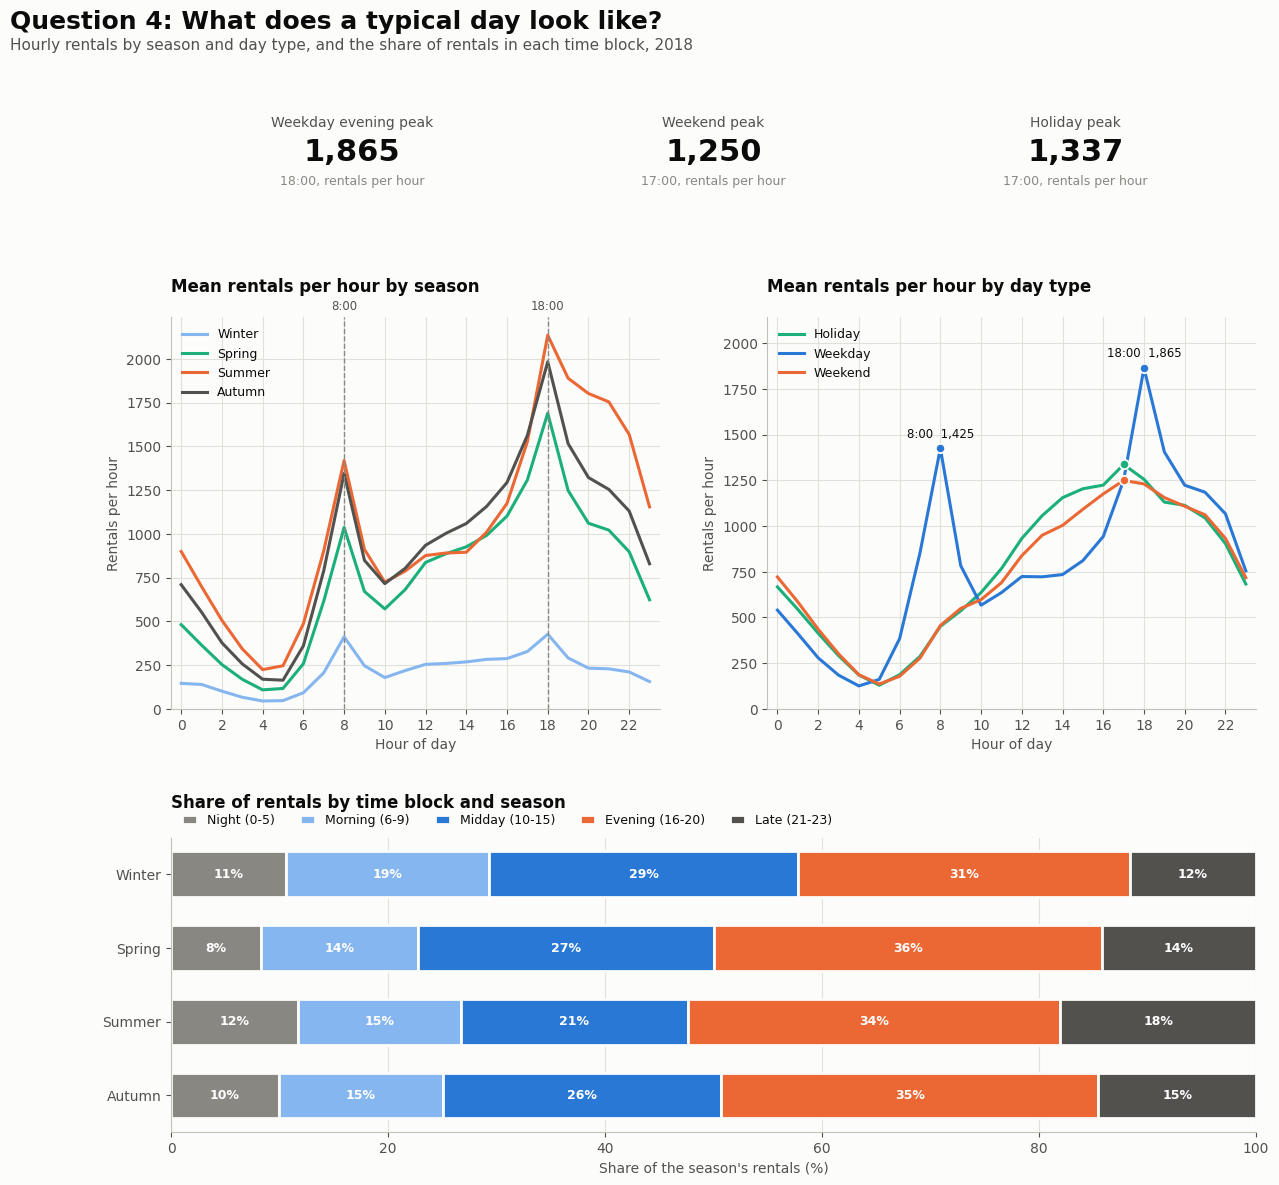

In [16]:
fig = dashboard_hours(season_profiles,
                      day_type_profiles,
                      peaks,
                      season_shares,
                      save_path=FIG_DIR / "q4_hours_dashboard_2018.png")

**Key Insight: Question 4 Findings**

Hourly rental patterns differ by day type. Weekdays show two peak periods, at 08:00 with an average of 1,425 rentals per hour and at 18:00 with 1,865. Weekends and holidays peak once, at 17:00, with 1,250 and 1,337 rentals per hour. All four seasons peak at 08:00 and 18:00. The evening block (16:00 to 20:00) holds the largest share of rentals in every season. Winter has the largest morning share at 19%, and summer has the largest late share at 18%. The holiday profile rests on 16 dates, so read its pattern with caution.

## **Step 16: Weekly, Weekday Analysis**

In [17]:
weekday_comparison_2018 = weekday_comparison(daily)
lowest_weekday_counts = lowest_day_by_week(daily)
weekly_highlights_2018 = weekly_highlights(weekly_summary(daily))

print(f"Weekday Comparison: ")
display(weekday_comparison_2018.round(2))

print(f"\nLowest Weekday Count: ")
display(lowest_weekday_counts.to_frame())

print(f"\nWeekly Highlights: ")
display(weekly_highlights_2018.round(2))

Weekday Comparison: 


,weekday,open_dates,mean_daily_rentals,mean_excluding_holidays,gap_to_best_pct
0,Friday,46,19798.22,20180.56,0.00
1,Saturday,46,18575.07,18772.32,6.18
2,Sunday,46,16528.39,16449.91,16.52
3,Monday,48,18553.75,18686.47,6.29
4,Tuesday,44,18973.95,18993.19,4.16
5,Wednesday,46,19594.54,18482.20,1.03
6,Thursday,46,18146.17,18775.18,8.34



Lowest Weekday Count: 


,lowest_week_count
Friday,1
Saturday,6
Sunday,14
Monday,5
Tuesday,5
Wednesday,3
Thursday,6



Weekly Highlights: 


,highlight,week_number,start_date,end_date,mean_daily_rentals
0,Highest,29,2018-06-15,2018-06-21,33212.71
1,Weakest,9,2018-01-26,2018-02-01,3586.71


## **Step 17: Assertions**

In [18]:
EXPECTED_WEEKS_COUNT = 49
EXPECTED_COMPLETE_WEEKS = 40
EXPECTED_PARTIAL_WEEKS_COUNT = 9
EXPECTED_DAYS_OF_THE_WEEK_COUNT = 7

# 1. Open dates per weekday and total open dates
expected_open_dates = pd.Series(
    [46, 46, 46, 48, 44, 46, 46],
    index=WEEK_ORDER,
    name="open_dates",
)

actual_open_dates = (
    weekday_comparison_2018.set_index("weekday")["open_dates"]
    .reindex(WEEK_ORDER)
)

assert actual_open_dates.equals(expected_open_dates), (
    f"Open dates: expected {expected_open_dates.to_dict()}, "
    f"got {actual_open_dates.to_dict()}"
)

assert actual_open_dates.sum() == EXPECTED_TOTAL_OPEN_DATES, (
    f"Total open dates: expected {EXPECTED_TOTAL_OPEN_DATES}, got {actual_open_dates.sum()}"
)

# 2. Weekday means multiplied by open dates equal total rentals
calculated_total = (
    weekday_comparison_2018["mean_daily_rentals"]
    * weekday_comparison_2018["open_dates"]
).sum()

actual_total = daily["daily_rentals"].sum()

assert np.isclose(calculated_total, actual_total), (
    f"Total rentals: expected {actual_total}, got {calculated_total}"
)

# Independent daily totals from the hourly dataset
daily18_check = (
    df18.groupby(["date", "day_name"], as_index=False)
    ["rented_bike_count"]
    .sum()
    .rename(columns={"rented_bike_count": "daily_rentals"})
)

# 3. Sunday mean agrees with the direct calculation
sunday_direct = daily18_check.loc[
    daily18_check["day_name"] == "Sunday", "daily_rentals"
].mean()

sunday_summary = weekday_comparison_2018.loc[
    weekday_comparison_2018["weekday"] == "Sunday",
    "mean_daily_rentals",
].iloc[0]

assert np.isclose(sunday_summary, sunday_direct), (
    f"Sunday mean: expected {sunday_direct}, got {sunday_summary}"
)

# 4. Wednesday mean excluding holidays agrees with an independent calculation
wednesday_direct = daily18_check.loc[
    (daily18_check["day_name"] == "Wednesday")
    & (~daily18_check["date"].isin(HOLIDAYS)),
    "daily_rentals",
].mean()

wednesday_adjusted = weekday_comparison_2018.loc[
    weekday_comparison_2018["weekday"] == "Wednesday",
    "mean_excluding_holidays",
].iloc[0]

assert np.isclose(wednesday_adjusted, wednesday_direct), (
    f"Wednesday mean excluding holidays: expected {wednesday_direct}, "
    f"got {wednesday_adjusted}"
)

# 5. Lowest weekday counts cover all 40 complete weeks
assert lowest_weekday_counts.sum() == EXPECTED_COMPLETE_WEEKS, (
    f"Lowest weekday counts: expected {EXPECTED_COMPLETE_WEEKS}, got {lowest_weekday_counts.sum()}"
)

matrix_check = week_weekday_matrix(daily)
weekly_check = weekly_summary(daily)

complete_week_numbers = weekly_check.loc[
    weekly_check["days"] == 7, "week_number"
]

complete_matrix_check = matrix_check.loc[
    matrix_check.index.isin(complete_week_numbers), WEEK_ORDER
]

matrix_lowest_counts = (
    complete_matrix_check.idxmin(axis=1)
    .value_counts()
    .reindex(WEEK_ORDER, fill_value=0)
)

assert lowest_weekday_counts.equals(
    matrix_lowest_counts.rename("lowest_week_count")
), (
    f"Lowest weekday counts: expected {matrix_lowest_counts.to_dict()}, "
    f"got {lowest_weekday_counts.to_dict()}"
)

# 6. Weekly table has 49 rows, including 9 partial weeks
assert len(weekly_check) == EXPECTED_WEEKS_COUNT, (
    f"Weekly rows: expected {EXPECTED_WEEKS_COUNT}, got {len(weekly_check)}"
)

assert weekly_check["is_partial"].sum() == EXPECTED_PARTIAL_WEEKS_COUNT, (
    f"Partial weeks: expected {EXPECTED_PARTIAL_WEEKS_COUNT}, got {weekly_check['is_partial'].sum()}"
)

# 7. Weekly highlights agree with an independent complete week calculation
independent_weekly = (
    daily.groupby("week_number")
    .agg(
        start_date=("date", "min"),
        days=("date", "nunique"),
        mean_daily_rentals=("daily_rentals", "mean"),
    )
)

independent_complete = independent_weekly.loc[
    independent_weekly["days"] == EXPECTED_DAYS_OF_THE_WEEK_COUNT
]

expected_highest = independent_complete[
    "mean_daily_rentals"
].idxmax()

expected_weakest = independent_complete[
    "mean_daily_rentals"
].idxmin()

actual_highest = weekly_highlights_2018.loc[
    weekly_highlights_2018["highlight"] == "Highest"
].iloc[0]

actual_weakest = weekly_highlights_2018.loc[
    weekly_highlights_2018["highlight"] == "Weakest"
].iloc[0]

assert actual_highest["week_number"] == expected_highest, (
    f"Highest week: expected {expected_highest}, "
    f"got {actual_highest['week_number']}"
)

assert actual_weakest["week_number"] == expected_weakest, (
    f"Weakest week: expected {expected_weakest}, "
    f"got {actual_weakest['week_number']}"
)

assert actual_highest["start_date"] == independent_complete.loc[
    expected_highest, "start_date"
], "Highest week start date does not match"

assert actual_weakest["start_date"] == independent_complete.loc[
    expected_weakest, "start_date"
], "Weakest week start date does not match"

assert np.isclose(
    actual_highest["mean_daily_rentals"],
    independent_complete.loc[expected_highest, "mean_daily_rentals"],
), "Highest week mean does not match"

assert np.isclose(
    actual_weakest["mean_daily_rentals"],
    independent_complete.loc[expected_weakest, "mean_daily_rentals"],
), "Weakest week mean does not match"


# 8. Sunday gap to the best weekday agrees with direct weekday means
sunday_row = weekday_comparison_2018.loc[
    weekday_comparison_2018["weekday"] == "Sunday"
].iloc[0]

direct_weekday_means = (
    daily18_check.groupby("day_name")["daily_rentals"]
    .mean()
    .reindex(WEEK_ORDER)
)

direct_best_mean = direct_weekday_means.max()
direct_sunday_mean = direct_weekday_means.loc["Sunday"]

expected_sunday_gap_pct = (
    (direct_best_mean - direct_sunday_mean)
    / direct_best_mean
    * 100
)

actual_sunday_gap_pct = sunday_row["gap_to_best_pct"]

assert np.isclose(
    actual_sunday_gap_pct,
    expected_sunday_gap_pct,
    atol=0.01
), (
    f"Sunday gap: expected {expected_sunday_gap_pct:.2f}%, "
    f"got {actual_sunday_gap_pct:.2f}%"
)

assert np.isclose(expected_sunday_gap_pct, 16.52, atol=0.01), (
    f"Sunday gap reference: expected 16.52%, "
    f"got {expected_sunday_gap_pct:.2f}%"
)

print("All Question 5 Assertions PASSED.")

All Question 5 Assertions PASSED.


## **Step 18: Question 5 Dashboard**

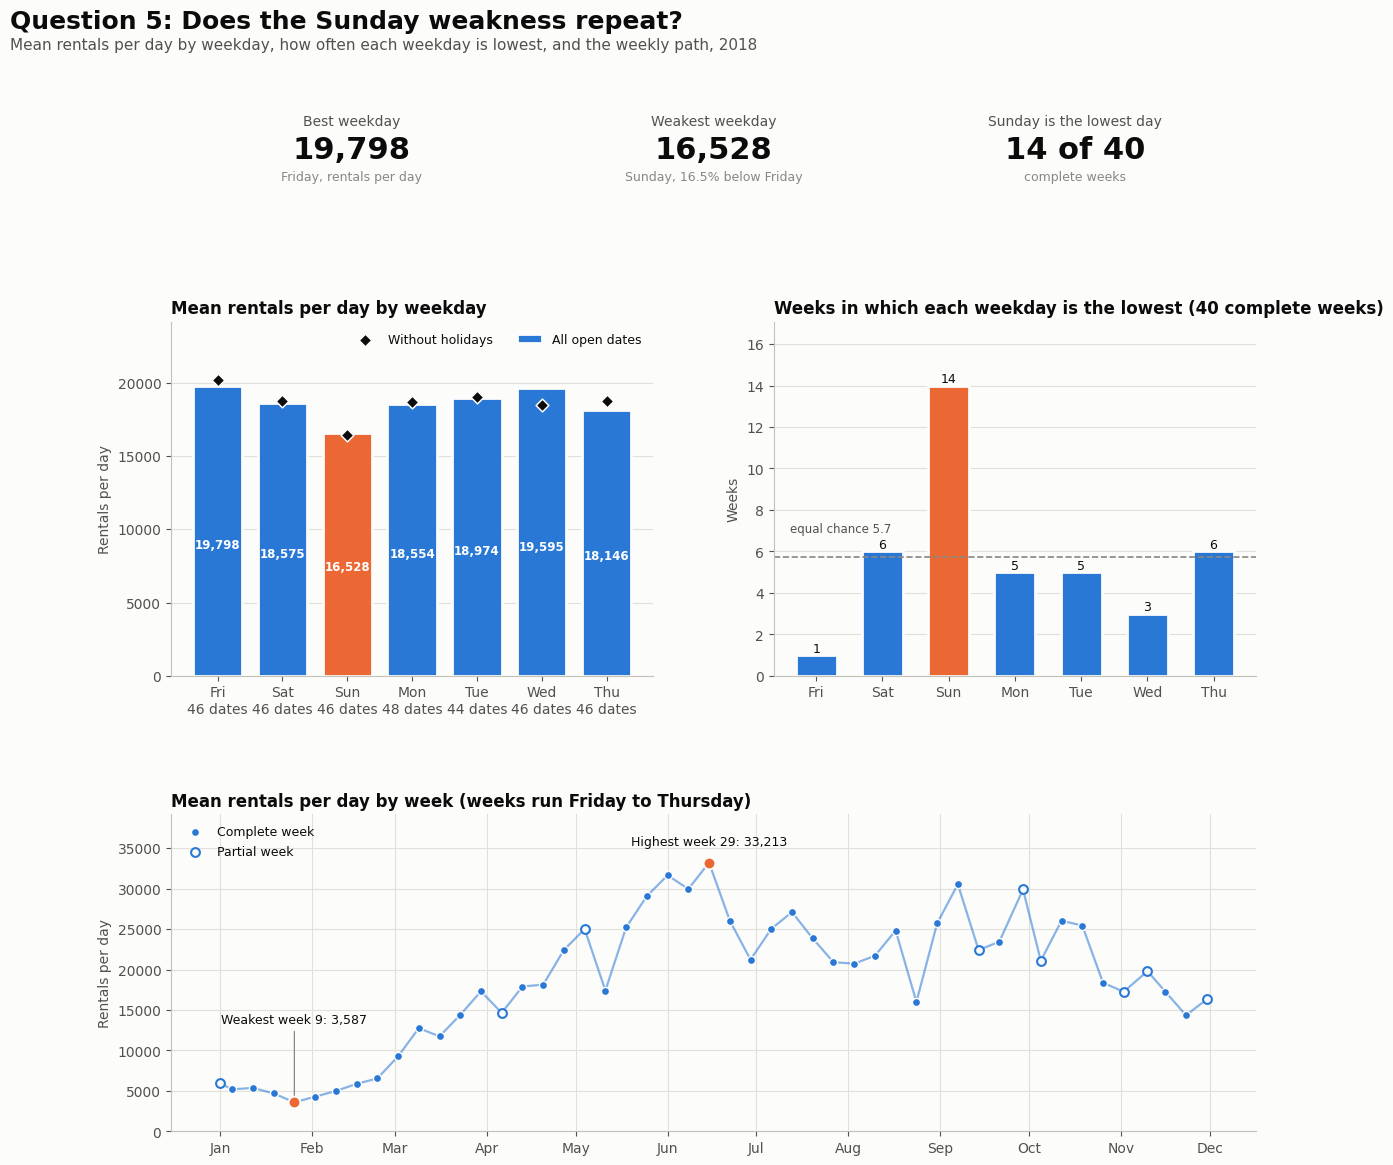

In [19]:
fig = dashboard_weekdays(weekday_comparison_2018,
                         lowest_weekday_counts,
                         weekly_summary(daily),
                         weekly_highlights_2018,
                         save_path=FIG_DIR / "q5_weekdays_dashboard_2018.png")

**Key Insight: Question 5 Findings:**

Friday recorded the highest weekday demand at 19,798 rentals per day. Sunday ranked last on both the all dates mean and the mean excluding holidays, at 16,528 and 16,450 rentals per day. This places Sunday 3,270 rentals per day (16.52%) below Friday. Sunday is the lowest day in 14 of 40 complete weeks, against about 6 if every weekday had an equal chance. Excluding holidays shifts Wednesday’s mean from 19,595 to 18,482 rentals per day, a reduction of 1,112. Five of Wednesday’s 46 dates are holidays, including 13 June, the busiest day. Without them, Wednesday falls from second place to sixth. Tuesday accounts for 4 of the 12 closed dates, so its mean rests on 44 open dates. The other weekday means rest on 46 or 48. The Sunday weakness repeats. In December 2017 Sunday averaged 3,978 rentals per day, 33.5% below that month’s mean of 5,978. Across 2018 Sunday sits 11.1% below the year’s mean. Within winter 2018, January and February, Sunday sits 19.0% below the mean of 5,116. Question 7 compares December 2017 with winter 2018 directly. The highest complete week was Week 29 (15 to 21 June), averaging 33,213 rentals per day. The weakest was Week 9 (26 January to 1 February), averaging 3,587. Weather may help explain this difference in weekly demand, and Question 6 tests it.

## **Step 19: Weather Table, Correlations and Rain Days**

In [20]:
weather_table = weather_daily_table(daily, weather)
correlations = season_correlations(weather_table)
weather_means = season_weather_means(weather_table)
rain = rain_effect(weather_table)

print("CORRELATIONS WITH DAILY RENTALS (Pearson r): ")
display(correlations.round(2))

print("\nWEATHER MEANS BY SEASON: ")
display(weather_means.round(2))

print("\nRAIN DAYS AGAINST DRY DAYS: ")
display(rain.round(1))

CORRELATIONS WITH DAILY RENTALS (Pearson r): 


,season,open_dates,temperature_r,humidity_r,rainfall_r,snowfall_r
0,Winter,59,0.64,0.25,-0.12,-0.20
1,Spring,90,0.65,-0.48,-0.46,NaN
2,Summer,92,-0.22,-0.51,-0.64,NaN
3,Autumn,81,0.54,-0.36,-0.56,-0.32
4,All year,322,0.72,0.02,-0.28,-0.23



WEATHER MEANS BY SEASON: 


,season,daily_rentals,temperature,humidity,rainfall,snowfall
0,Winter,5115.92,-2.86,46.55,0.61,4.38
1,Spring,17910.10,13.02,58.76,4.49,0.00
2,Summer,24817.76,26.58,64.98,6.08,0.00
3,Autumn,22098.79,13.84,59.12,2.81,1.52



RAIN DAYS AGAINST DRY DAYS: 


,season,dry_dates,rain_dates,dry_mean,rain_mean,gap_rentals,gap_pct
0,Winter,50,9,5227.2,4497.7,-729.5,-14.0
1,Spring,62,28,20899.9,11289.8,-9610.2,-46.0
2,Summer,57,35,27544.4,20377.3,-7167.1,-26.0
3,Autumn,62,19,23550.6,17361.4,-6189.2,-26.3


## **Step 20: Assertions**

In [21]:
EXPECTED_WEATHER_ROWS = 322
EXPECTED_SEASON_DATES = {"Winter": 59, "Spring": 90, "Summer": 92, "Autumn": 81}
EXPECTED_CONSTANT_SNOW_SEASONS = ["Spring", "Summer"]
EXPECTED_ALL_YEAR_TEMPERATURE_R = 0.72
EXPECTED_SUMMER_TEMPERATURE_R = -0.22
EXPECTED_RAIN_DATES = {"Winter": 9, "Spring": 28, "Summer": 35, "Autumn": 19}
EXPECTED_TOTAL_RAIN_DATES = 91
R_DECIMALS = 2
MIN_R = -1
MAX_R = 1

# Independent derivation from the hourly table
hourly_daily = (
    df18.groupby("date")
    .agg(
        rentals=("rented_bike_count", "sum"),
        temperature=("temperature", "mean"),
        rainfall=("rainfall", "sum"),
        snowfall=("snowfall", "sum"),
    )
)
hourly_daily["season"] = hourly_daily.index.month.map(SEASON_BY_MONTH)

# 1. The merged table keeps every open date once, with no gaps
assert len(weather_table) == EXPECTED_WEATHER_ROWS, (
    f"Weather table rows mismatch: expected {EXPECTED_WEATHER_ROWS}, got {len(weather_table)}"
)
assert weather_table["date"].is_unique, "Weather table holds a repeated date"
assert weather_table[["daily_rentals"] + WEATHER_FACTORS].notna().all().all(), (
    "Weather table holds missing values"
)

# 2. Open dates per season and all year
actual_season_dates = (
    correlations.set_index("season")["open_dates"].drop(ALL_YEAR_LABEL).to_dict()
)
assert actual_season_dates == EXPECTED_SEASON_DATES, (
    f"Season dates mismatch: expected {EXPECTED_SEASON_DATES}, got {actual_season_dates}"
)
assert correlations.set_index("season").loc[ALL_YEAR_LABEL, "open_dates"] == EXPECTED_WEATHER_ROWS, (
    "All year dates mismatch"
)

# 3. Summer temperature r against numpy on the hourly roll-up
summer_hourly = hourly_daily[hourly_daily["season"] == "Summer"]
expected_summer_r = np.corrcoef(summer_hourly["rentals"], summer_hourly["temperature"])[0, 1]
actual_summer_r = correlations.set_index("season").loc["Summer", "temperature_r"]

assert np.isclose(actual_summer_r, expected_summer_r), (
    f"Summer temperature r mismatch: expected {expected_summer_r:.4f}, got {actual_summer_r:.4f}"
)
assert round(actual_summer_r, R_DECIMALS) == EXPECTED_SUMMER_TEMPERATURE_R, (
    f"Summer temperature r mismatch: expected {EXPECTED_SUMMER_TEMPERATURE_R}, got {round(actual_summer_r, R_DECIMALS)}"
)

# 4. All year temperature r against numpy
expected_all_year_r = np.corrcoef(hourly_daily["rentals"], hourly_daily["temperature"])[0, 1]
actual_all_year_r = correlations.set_index("season").loc[ALL_YEAR_LABEL, "temperature_r"]

assert np.isclose(actual_all_year_r, expected_all_year_r), (
    f"All year temperature r mismatch: expected {expected_all_year_r:.4f}, got {actual_all_year_r:.4f}"
)
assert round(actual_all_year_r, R_DECIMALS) == EXPECTED_ALL_YEAR_TEMPERATURE_R, (
    f"All year temperature r mismatch: expected {EXPECTED_ALL_YEAR_TEMPERATURE_R}, got {round(actual_all_year_r, R_DECIMALS)}"
)

# 5. Snowfall never changes in spring and summer, so r does not exist there
nan_snow_seasons = correlations.loc[correlations["snowfall_r"].isna(), "season"].tolist()
assert nan_snow_seasons == EXPECTED_CONSTANT_SNOW_SEASONS, (
    f"Constant snow seasons mismatch: expected {EXPECTED_CONSTANT_SNOW_SEASONS}, got {nan_snow_seasons}"
)
for season_name in EXPECTED_CONSTANT_SNOW_SEASONS:
    season_snow_total = hourly_daily.loc[hourly_daily["season"] == season_name, "snowfall"].sum()
    assert season_snow_total == 0, (
        f"{season_name} snowfall total mismatch: expected 0, got {season_snow_total}"
    )

# 6. Every r sits between -1 and 1
r_values = correlations[[f"{factor}_r" for factor in WEATHER_FACTORS]].stack().dropna()
assert r_values.between(MIN_R, MAX_R).all(), "A correlation falls outside -1 to 1"

# 7. Rain date counts per season and in total
actual_rain_dates = rain.set_index("season")["rain_dates"].to_dict()
assert actual_rain_dates == EXPECTED_RAIN_DATES, (
    f"Rain dates mismatch: expected {EXPECTED_RAIN_DATES}, got {actual_rain_dates}"
)
assert rain["rain_dates"].sum() == EXPECTED_TOTAL_RAIN_DATES, (
    f"Total rain dates mismatch: expected {EXPECTED_TOTAL_RAIN_DATES}, got {rain['rain_dates'].sum()}"
)
assert (hourly_daily["rainfall"] > 0).sum() == EXPECTED_TOTAL_RAIN_DATES, (
    "Rain dates in the hourly table do not match the total"
)

# 8. Dry and rain dates add up to each season, and the two means rebuild the season mean
for season_name, season_dates in EXPECTED_SEASON_DATES.items():
    season_row = rain.set_index("season").loc[season_name]
    assert season_row["dry_dates"] + season_row["rain_dates"] == season_dates, (
        f"{season_name} dry and rain dates mismatch: expected {season_dates}, "
        f"got {season_row['dry_dates'] + season_row['rain_dates']}"
    )
    rebuilt_mean = (
        season_row["dry_dates"] * season_row["dry_mean"]
        + season_row["rain_dates"] * season_row["rain_mean"]
    ) / season_dates
    expected_mean = hourly_daily.loc[hourly_daily["season"] == season_name, "rentals"].mean()
    assert np.isclose(rebuilt_mean, expected_mean), (
        f"{season_name} mean mismatch: expected {expected_mean:.2f}, got {rebuilt_mean:.2f}"
    )

# 9. Spring rain gap against a direct calculation
spring_hourly = hourly_daily[hourly_daily["season"] == "Spring"]
expected_spring_gap = (
    spring_hourly.loc[spring_hourly["rainfall"] > 0, "rentals"].mean()
    / spring_hourly.loc[spring_hourly["rainfall"] == 0, "rentals"].mean()
    - 1
) * 100
actual_spring_gap = rain.set_index("season").loc["Spring", "gap_pct"]

assert np.isclose(actual_spring_gap, expected_spring_gap), (
    f"Spring rain gap mismatch: expected {expected_spring_gap:.2f}, got {actual_spring_gap:.2f}"
)

print("All Question 6 Assertiona PASSED.")

All Question 6 Assertiona PASSED.


## **Step 21: Question 6 Dashboard**

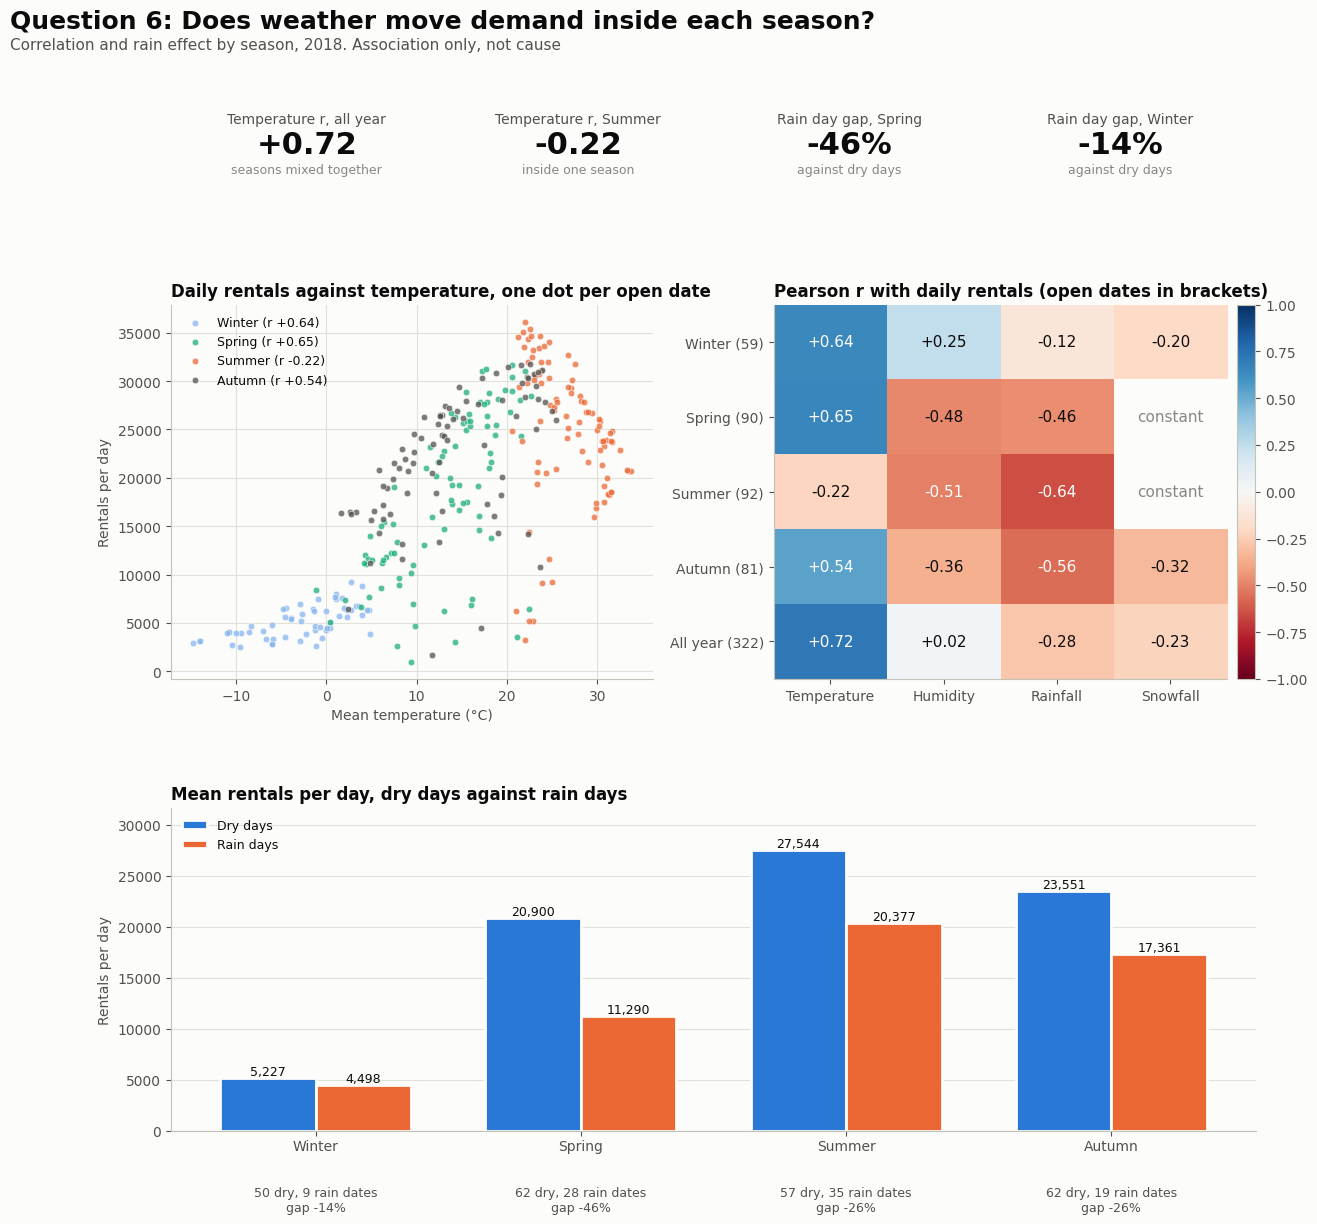

In [22]:
fig = dashboard_weather(
    weather_table,
    correlations,
    rain,
    save_path=FIG_DIR / "q6_weather_dashboard_2018.png",
)

**Key Insight: Question 6 Findings**

Temperature moves demand across the year. The all year r is +0.72. Most of that link comes from the gap between seasons. Inside each season the picture changes. Temperature r is +0.64 in Winter, +0.65 in Spring and +0.54 in Autumn. In Summer it turns to -0.22. The hottest summer days bring no extra demand. Rain is the clearer drag inside a season. Rainfall r is -0.65 in Summer, -0.56 in Autumn and -0.46 in Spring. Rain days fall below dry days by 46% in Spring (11,290 against 20,900 rentals per day), 26% in Summer, 26% in Autumn and 14% in Winter. Winter rain (r -0.12) and snow (r -0.20) sit below the 0.26 that 59 dates need, so Winter shows no clear link to either. Spring and Summer record no snow, so snow r does not exist there. Autumn snow rests on 3 dates, so do not read its r of -0.32. These figures show association only. Rain days also bring humidity and cloud, and Question 6 cannot separate them.

## **Step 22: Holidays, Closed Dates and the Winter Comparison**

In [23]:
df17 = clean_df[clean_df["year"] == 2017].copy()
daily17 = daily_table(df17)
weather17 = daily_weather(df17)

peers = holiday_vs_peers(daily)
day_types = day_type_summary(daily)
closed = closed_dates_table(full_calendar)
partial = partial_dates(df18)
winter = winter_comparison(daily17, weather17, daily, weather)
winter_difference = winter_gap(winter)
december_sunday = sunday_gap(daily17)
winter_sunday = sunday_gap(daily[daily["date"].dt.month.isin([1, 2])])

print("HOLIDAYS AGAINST PEERS: ")
display(peers.round(1))

print("\nDAY TYPES: ")
display(day_types.round(0))

print("\nCLOSED DATES: ")
display(closed)

print("\nPARTIAL DATES: ")
display(partial)

print("\nWINTER 2018 AGAINST DECEMBER 2017: ")
display(winter.round(2))

print("\nWINTER GAP: ")
display(pd.Series(winter_difference).round(2).to_frame("value"))

print("\nSUNDAY GAP: ")
display(pd.DataFrame({"December 2017": december_sunday, "Winter 2018": winter_sunday}).round(2))

HOLIDAYS AGAINST PEERS: 


,date,day_name,holiday_rentals,peer_dates,peer_mean,gap_pct
0,2018-01-01,Monday,4290,22,5092.0,-15.8
1,2018-02-15,Thursday,3484,18,6231.6,-44.1
2,2018-02-16,Friday,2593,18,6231.6,-58.4
3,2018-02-17,Saturday,3118,7,4352.9,-28.4
4,2018-03-01,Thursday,5132,21,12772.6,-59.8
5,2018-05-05,Saturday,25353,7,22770.9,11.3
6,2018-05-07,Monday,28140,20,24020.4,17.2
7,2018-05-22,Tuesday,13790,20,24020.4,-42.6
8,2018-06-06,Wednesday,30498,19,29906.8,2.0
9,2018-06-13,Wednesday,36149,19,29906.8,20.9



DAY TYPES: 


,day_type,open_dates,mean_daily_rentals,median_daily_rentals
0,Weekday,217,19035.0,21015.0
1,Weekend,89,17598.0,18363.0
2,Holiday,16,18134.0,19312.0



CLOSED DATES: 


,date,day_name,month,is_holiday
0,2018-04-11,Wednesday,4,False
1,2018-05-10,Thursday,5,False
2,2018-09-18,Tuesday,9,False
3,2018-09-19,Wednesday,9,False
4,2018-09-28,Friday,9,False
5,2018-09-30,Sunday,9,False
6,2018-10-02,Tuesday,10,False
7,2018-10-04,Thursday,10,False
8,2018-10-09,Tuesday,10,True
9,2018-11-03,Saturday,11,False


... (4 outputs left out)


WINTER GAP: 


,value
gap_rentals,-862.47
gap_pct,-14.43
standard_error,411.50
t_value,-2.10



SUNDAY GAP: 


,December 2017,Winter 2018
sunday_dates,5.00,8.00
sunday_mean,3977.60,4142.38
period_mean,5978.39,5115.92
gap_pct,-33.47,-19.03


## **Step 23: Assertions**

In [24]:
EXPECTED_HOLIDAY_DATES = 16
EXPECTED_HOLIDAYS_BELOW_PEERS = 10
EXPECTED_CLOSED_BY_MONTH = {4: 1, 5: 1, 9: 4, 10: 3, 11: 3}
EXPECTED_CLOSED_BY_WEEKDAY = {
    "Tuesday": 4, "Wednesday": 2, "Thursday": 2, "Friday": 2, "Saturday": 1, "Sunday": 1,
}
EXPECTED_CLOSED_HOLIDAY = pd.Timestamp("2018-10-09")
EXPECTED_DAY_TYPE_DATES = {"Weekday": 217, "Weekend": 89, "Holiday": 16}
EXPECTED_WINTER_DATES = {
    "December 2017": 31, "January 2018": 31, "February 2018": 28, "Winter 2018": 59,
}
EXPECTED_DECEMBER_TOTAL = df17["rented_bike_count"].sum()
EXPECTED_WINTER_GAP_PCT = -14.4
EXPECTED_DECEMBER_SUNDAY_GAP_PCT = -33.5
EXPECTED_WINTER_SUNDAY_GAP_PCT = -19.0
GAP_DECIMALS = 1
THIRTEEN_JUNE = pd.Timestamp("2018-06-13")

# 1. Holiday count and dates
holiday_dates_in_daily = set(daily.loc[daily["day_type"] == "Holiday", "date"])
assert len(peers) == EXPECTED_HOLIDAY_DATES, (
    f"Holiday rows mismatch: expected {EXPECTED_HOLIDAY_DATES}, got {len(peers)}"
)
assert set(peers["date"]) == holiday_dates_in_daily, "Holiday dates differ from the daily table"
assert set(peers["date"]) <= HOLIDAYS, "A holiday date falls outside the verified set"

# 2. Every holiday has peers, and the count below peers matches
assert (peers["peer_dates"] > 0).all(), "A holiday has no ordinary peers"
holidays_below_peers = int((peers["gap_pct"] < 0).sum())
assert holidays_below_peers == EXPECTED_HOLIDAYS_BELOW_PEERS, (
    f"Holidays below peers mismatch: expected {EXPECTED_HOLIDAYS_BELOW_PEERS}, got {holidays_below_peers}"
)

# 3. 13 June against a direct calculation from the hourly table
june_ordinary = hourly_daily[
    (hourly_daily.index.month == 6)
    & (~hourly_daily.index.isin(HOLIDAYS))
    & (hourly_daily.index.dayofweek < 5)
]["rentals"]
expected_june_gap = (
    daily.loc[daily["date"] == THIRTEEN_JUNE, "daily_rentals"].iloc[0] / june_ordinary.mean() - 1
) * 100
actual_june_gap = peers.set_index("date").loc[THIRTEEN_JUNE, "gap_pct"]

assert np.isclose(actual_june_gap, expected_june_gap), (
    f"13 June gap mismatch: expected {expected_june_gap:.2f}, got {actual_june_gap:.2f}"
)

# 4. Day type counts and the weighted mean rebuild the overall mean
actual_day_type_dates = day_types.set_index("day_type")["open_dates"].to_dict()
assert actual_day_type_dates == EXPECTED_DAY_TYPE_DATES, (
    f"Day type dates mismatch: expected {EXPECTED_DAY_TYPE_DATES}, got {actual_day_type_dates}"
)
rebuilt_overall_mean = (
    day_types["open_dates"] * day_types["mean_daily_rentals"]
).sum() / day_types["open_dates"].sum()
assert np.isclose(rebuilt_overall_mean, daily["daily_rentals"].mean()), (
    f"Overall mean mismatch: expected {daily['daily_rentals'].mean():.2f}, got {rebuilt_overall_mean:.2f}"
)

# 5. Closed dates match the audit, by month and by weekday
assert set(closed["date"]) == set(absent_dates), "Closed dates differ from the audit list"
actual_closed_by_month = closed.groupby("month").size().to_dict()
assert actual_closed_by_month == EXPECTED_CLOSED_BY_MONTH, (
    f"Closed by month mismatch: expected {EXPECTED_CLOSED_BY_MONTH}, got {actual_closed_by_month}"
)
actual_closed_by_weekday = closed.groupby("day_name").size().to_dict()
assert actual_closed_by_weekday == EXPECTED_CLOSED_BY_WEEKDAY, (
    f"Closed by weekday mismatch: expected {EXPECTED_CLOSED_BY_WEEKDAY}, got {actual_closed_by_weekday}"
)

# 6. Exactly one closed date is a holiday, and it holds no rows
closed_holidays = closed.loc[closed["is_holiday"], "date"].tolist()
assert closed_holidays == [EXPECTED_CLOSED_HOLIDAY], (
    f"Closed holiday mismatch: expected {[EXPECTED_CLOSED_HOLIDAY]}, got {closed_holidays}"
)
assert EXPECTED_CLOSED_HOLIDAY not in set(df18["date"]), "The closed holiday holds hourly rows"

# 7. The only partial date is 6 October with 17 open hours
assert partial["date"].tolist() == [INCOMPLETE_DATE], (
    f"Partial dates mismatch: expected {[INCOMPLETE_DATE]}, got {partial['date'].tolist()}"
)
assert partial["open_hours"].tolist() == [INCOMPLETE_DATE_OPEN_HOURS], (
    f"Partial hours mismatch: expected {[INCOMPLETE_DATE_OPEN_HOURS]}, got {partial['open_hours'].tolist()}"
)

# 8. Winter table: dates, December total and Winter rebuilt from January and February
actual_winter_dates = winter.set_index("period")["open_dates"].to_dict()
assert actual_winter_dates == EXPECTED_WINTER_DATES, (
    f"Winter dates mismatch: expected {EXPECTED_WINTER_DATES}, got {actual_winter_dates}"
)
assert daily17["daily_rentals"].sum() == EXPECTED_DECEMBER_TOTAL, (
    f"December total mismatch: expected {EXPECTED_DECEMBER_TOTAL}, got {daily17['daily_rentals'].sum()}"
)
winter_by_period = winter.set_index("period")
rebuilt_winter_mean = (
    winter_by_period.loc["January 2018", "open_dates"] * winter_by_period.loc["January 2018", "mean_daily_rentals"]
    + winter_by_period.loc["February 2018", "open_dates"] * winter_by_period.loc["February 2018", "mean_daily_rentals"]
) / winter_by_period.loc["Winter 2018", "open_dates"]
assert np.isclose(rebuilt_winter_mean, winter_by_period.loc["Winter 2018", "mean_daily_rentals"]), (
    f"Winter mean mismatch: expected {winter_by_period.loc['Winter 2018', 'mean_daily_rentals']:.2f}, got {rebuilt_winter_mean:.2f}"
)
assert np.isclose(
    winter_by_period.loc["Winter 2018", "mean_daily_rentals"],
    seasons.set_index("season").loc["Winter", "mean_daily_rentals"],
), "Winter comparison mean differs from the Question 3 season table"

# 9. The winter gap, its standard error and the Sunday gaps
direct_gap = (
    winter_by_period.loc["Winter 2018", "mean_daily_rentals"]
    - winter_by_period.loc["December 2017", "mean_daily_rentals"]
)
assert np.isclose(winter_difference["gap_rentals"], direct_gap), (
    f"Winter gap mismatch: expected {direct_gap:.2f}, got {winter_difference['gap_rentals']:.2f}"
)
assert round(winter_difference["gap_pct"], GAP_DECIMALS) == EXPECTED_WINTER_GAP_PCT, (
    f"Winter gap percent mismatch: expected {EXPECTED_WINTER_GAP_PCT}, got {round(winter_difference['gap_pct'], GAP_DECIMALS)}"
)
assert round(december_sunday["gap_pct"], GAP_DECIMALS) == EXPECTED_DECEMBER_SUNDAY_GAP_PCT, (
    f"December Sunday gap mismatch: expected {EXPECTED_DECEMBER_SUNDAY_GAP_PCT}, got {round(december_sunday['gap_pct'], GAP_DECIMALS)}"
)
assert round(winter_sunday["gap_pct"], GAP_DECIMALS) == EXPECTED_WINTER_SUNDAY_GAP_PCT, (
    f"Winter Sunday gap mismatch: expected {EXPECTED_WINTER_SUNDAY_GAP_PCT}, got {round(winter_sunday['gap_pct'], GAP_DECIMALS)}"
)

print("All Question 7 Assertions PASSED.")

All Question 7 Assertions PASSED.


## **Step 24: Question 7 Dashboard**

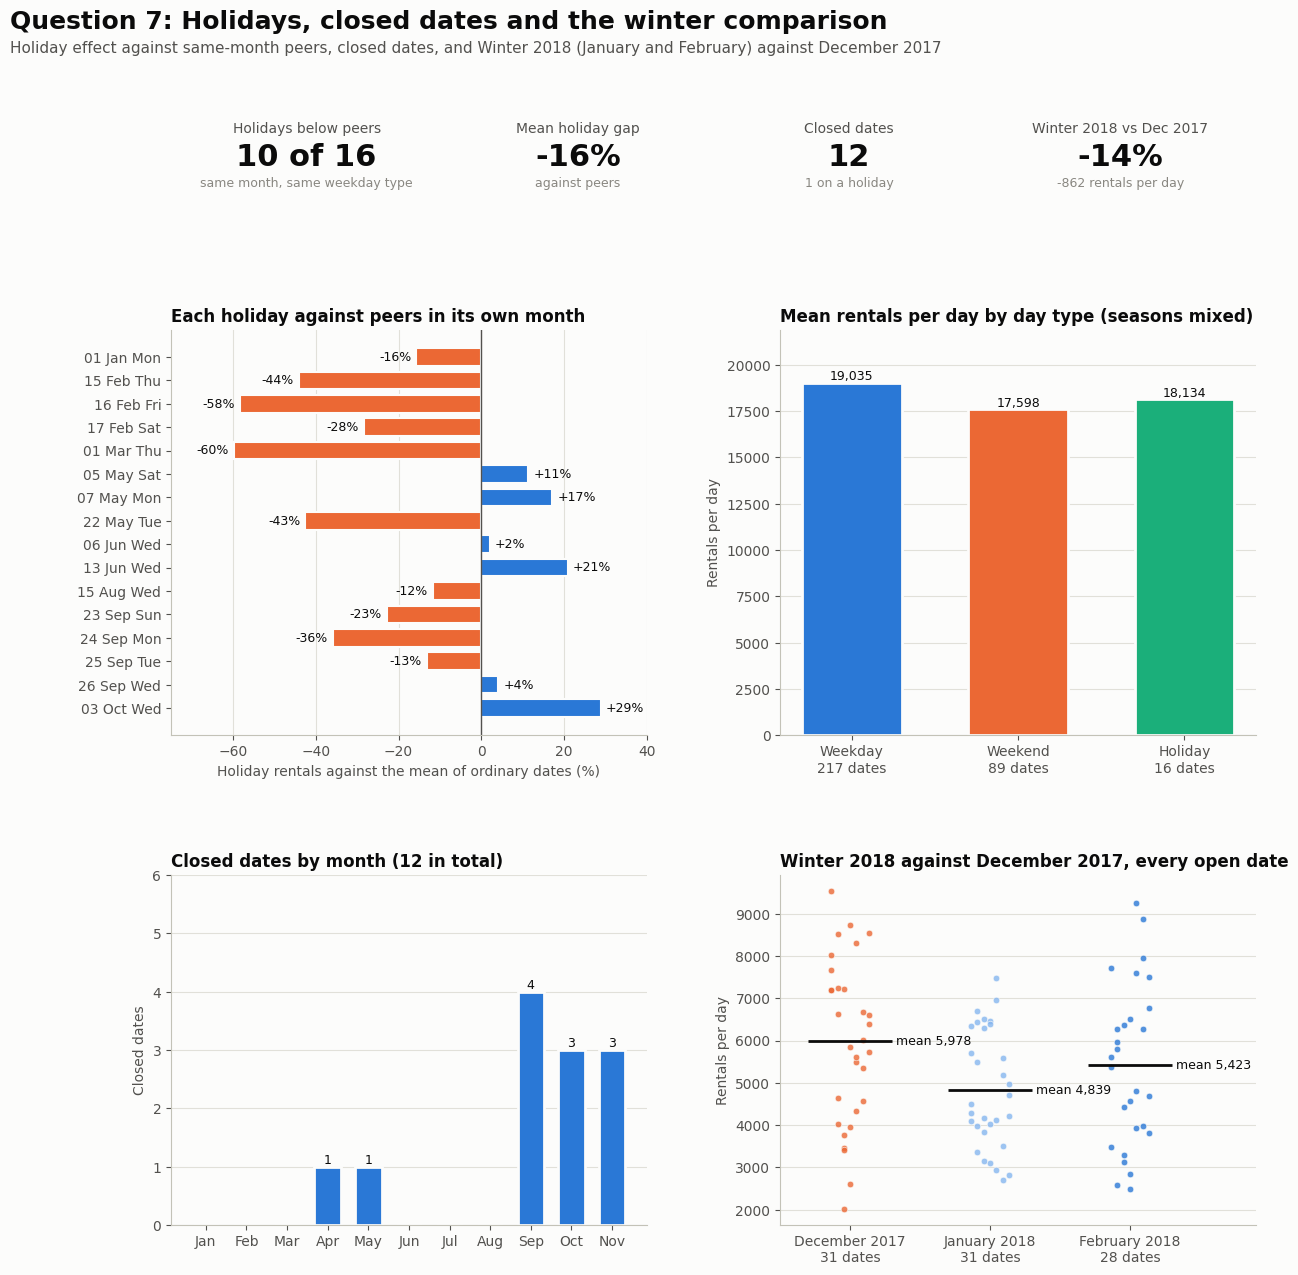

In [25]:
fig = dashboard_holidays(
    peers,
    day_types,
    closed,
    winter,
    daily17,
    daily,
    winter_difference,
    save_path=FIG_DIR / "q7_holidays_dashboard_2018.png",
)

**Key Insight: Question 7 Findings**

Holidays do not lift demand. Against ordinary dates in the same month and the same weekday type, 10 of 16 open holidays fall below. The mean gap is -15.5% and the median is -14.5%. The three Seollal dates sit 28% to 58% below peers. Chuseok shows the same pattern on three of four dates, then the substitute day (26 September) sits 4% above. Six holidays sit above peers. The strongest is 3 October at +29%. The busiest day of the year, 13 June (an election day), sits 21% above. The raw day type means (Weekday 19,035, Weekend 17,598, Holiday 18,134 rentals per day) mix seasons, so do not use them to rank holidays. The centre closed on 12 dates. Ten fall between September and November. Tuesday accounts for 4. One closed date, 9 October, is a verified holiday. The data gives no reason for any closure. 6 October is the only partial date, with 17 open hours. Winter 2018 averages 5,116 rentals per day against 5,978 in December 2017. That is 862 fewer, a gap of 14.4%. January averages 4,839 (19.1% below December) and February 5,423 (9.3% below). The gap is 2.1 standard errors wide, so it is borderline. December 2017 was not milder. It held more snow (8.9 cm per day against 4.4) and a similar temperature (-1.9 C against -2.9 C), yet demand ran higher. Weather does not explain the gap. Winter holds 4 holidays, 3 of them Seollal days among the lowest of the period. December holds 1. Sunday stays weak in both periods, 33.5% below the December mean and 19.0% below the Winter mean. One December and one winter cannot separate a seasonal change from a trend in the business.